In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests
from sklearn.preprocessing import StandardScaler
import gzip
import os
import gzip
from io import BytesIO

In [ ]:
from google.colab import files

arquivos = files.upload()

Saving GSE276323_Normalized_space_DNA_methylation.csv.gz to GSE276323_Normalized_space_DNA_methylation.csv (1).gz


In [ ]:
print("Arquivos enviados:")

for arquivo in arquivos.keys():
    print("-", arquivo)

Arquivos enviados:
- GSE276323_Normalized_space_DNA_methylation.csv (1).gz


In [ ]:
arquivo = "/content/GSE276323_Normalized_space_DNA_methylation.csv.gz"

dados = pd.read_csv(arquivo, index_col=0)

print("Dimensões:", dados.shape)
print("Número de regiões de metilação:", dados.shape[0])
print("Número de amostras:", dados.shape[1])

display(dados.head())

Dimensões: (776047, 6)
Número de regiões de metilação: 776047
Número de amostras: 6


,206667650075_R07C01,206667650093_R06C01,206667650062_R05C01,206677660051_R03C01,206667650069_R05C01,206667650068_R06C01
cg26928153,0.851708,0.854037,0.847283,0.813049,0.841833,0.838628
cg16269199,0.800962,0.814424,0.806662,0.769770,0.767876,0.765659
cg13869341,0.793296,0.786252,0.799645,0.830927,0.829570,0.827117
cg24669183,0.803232,0.791862,0.802825,0.805242,0.847606,0.828913
cg26679879,0.436227,0.459748,0.477806,0.406422,0.437614,0.427810


In [ ]:
print("Valores ausentes:", dados.isna().sum().sum())
print("Regiões duplicadas:", dados.index.duplicated().sum())
print("Colunas duplicadas:", dados.columns.duplicated().sum())

print("\nMenor valor:", dados.min().min())
print("Maior valor:", dados.max().max())

print("\nResumo estatístico:")
display(dados.describe().round(4))

Valores ausentes: 0
Regiões duplicadas: 0
Colunas duplicadas: 0

Menor valor: 0.0350139587422
Maior valor: 0.996096827043346

Resumo estatístico:


,206667650075_R07C01,206667650093_R06C01,206667650062_R05C01,206677660051_R03C01,206667650069_R05C01,206667650068_R06C01
count,776047.0000,776047.0000,776047.0000,776047.0000,776047.0000,776047.0000
mean,0.5947,0.5945,0.5946,0.5935,0.5941,0.5930
std,0.3168,0.3180,0.3169,0.3201,0.3197,0.3215
min,0.0385,0.0390,0.0384,0.0350,0.0387,0.0387
25%,0.2520,0.2488,0.2538,0.2419,0.2407,0.2348
50%,0.7574,0.7554,0.7518,0.7588,0.7635,0.7624
75%,0.8624,0.8641,0.8637,0.8653,0.8645,0.8657
max,0.9952,0.9961,0.9939,0.9901,0.9959,0.9955


In [ ]:
resumo_amostras = dados.agg(
    ["mean", "median", "std", "min", "max"]
).T

display(resumo_amostras.round(4))

,mean,median,std,min,max
206667650075_R07C01,0.5947,0.7574,0.3168,0.0385,0.9952
206667650093_R06C01,0.5945,0.7554,0.3180,0.0390,0.9961
206667650062_R05C01,0.5946,0.7518,0.3169,0.0384,0.9939
206677660051_R03C01,0.5935,0.7588,0.3201,0.0350,0.9901
206667650069_R05C01,0.5941,0.7635,0.3197,0.0387,0.9959
206667650068_R06C01,0.5930,0.7624,0.3215,0.0387,0.9955


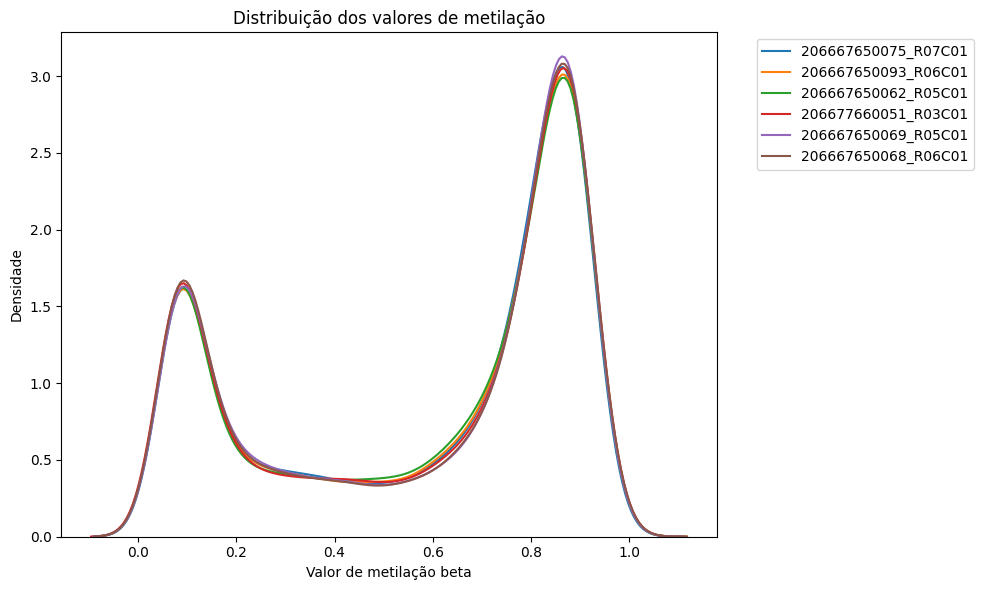

In [ ]:
dados_amostra = dados.sample(
    n=min(20000, len(dados)),
    random_state=42
)

plt.figure(figsize=(10, 6))

for coluna in dados_amostra.columns:
    sns.kdeplot(
        dados_amostra[coluna],
        label=coluna,
        warn_singular=False
    )

plt.title("Distribuição dos valores de metilação")
plt.xlabel("Valor de metilação beta")
plt.ylabel("Densidade")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

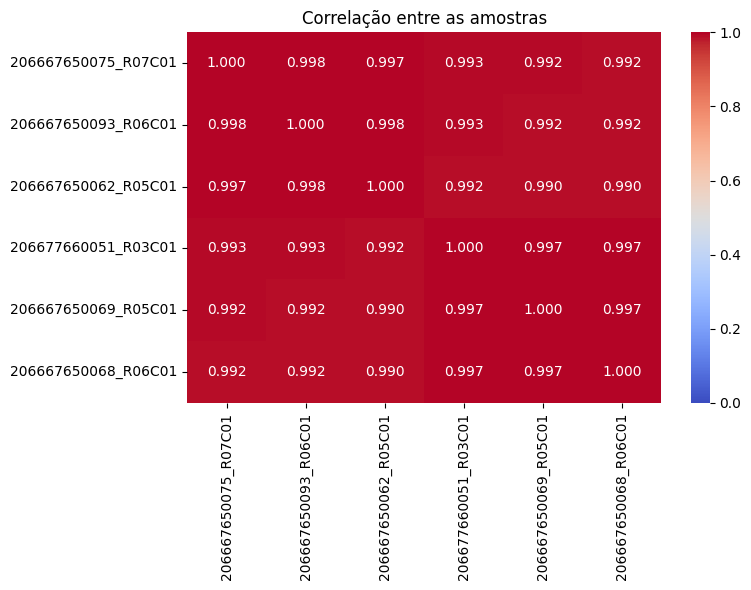

,206667650075_R07C01,206667650093_R06C01,206667650062_R05C01,206677660051_R03C01,206667650069_R05C01,206667650068_R06C01
206667650075_R07C01,1.0000,0.9976,0.9968,0.9926,0.9922,0.9921
206667650093_R06C01,0.9976,1.0000,0.9977,0.9927,0.9920,0.9918
206667650062_R05C01,0.9968,0.9977,1.0000,0.9921,0.9900,0.9903
206677660051_R03C01,0.9926,0.9927,0.9921,1.0000,0.9965,0.9975
206667650069_R05C01,0.9922,0.9920,0.9900,0.9965,1.0000,0.9974
206667650068_R06C01,0.9921,0.9918,0.9903,0.9975,0.9974,1.0000


In [ ]:
correlacao = dados.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlacao,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=0,
    vmax=1
)

plt.title("Correlação entre as amostras")
plt.tight_layout()
plt.show()

display(correlacao.round(4))

In [ ]:
metadados = pd.DataFrame({
    "amostra": [
        "206667650075_R07C01",
        "206667650093_R06C01",
        "206667650062_R05C01",
        "206677660051_R03C01",
        "206667650069_R05C01",
        "206667650068_R06C01"
    ],
    "GSM": [
        "GSM8496586",
        "GSM8496587",
        "GSM8496588",
        "GSM8496589",
        "GSM8496590",
        "GSM8496591"
    ]
})

display(metadados)

,amostra,GSM
0,206667650075_R07C01,GSM8496586
1,206667650093_R06C01,GSM8496587
2,206667650062_R05C01,GSM8496588
3,206677660051_R03C01,GSM8496589
4,206667650069_R05C01,GSM8496590
5,206667650068_R06C01,GSM8496591


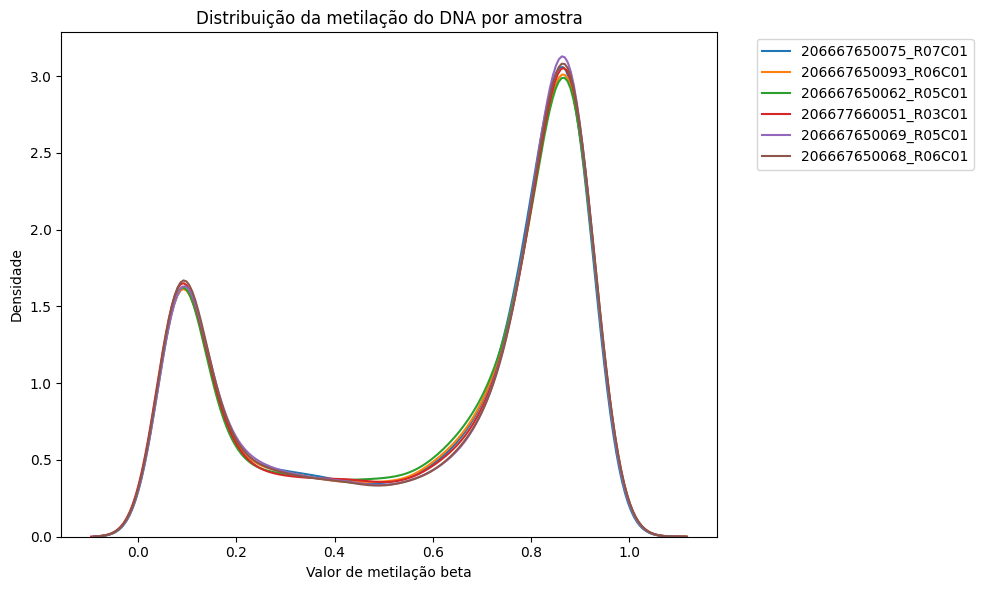

In [ ]:
plt.figure(figsize=(10, 6))

dados_amostra = dados.sample(
    n=min(20000, len(dados)),
    random_state=42
)

for coluna in dados_amostra.columns:
    sns.kdeplot(
        dados_amostra[coluna],
        label=coluna
    )

plt.title("Distribuição da metilação do DNA por amostra")
plt.xlabel("Valor de metilação beta")
plt.ylabel("Densidade")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

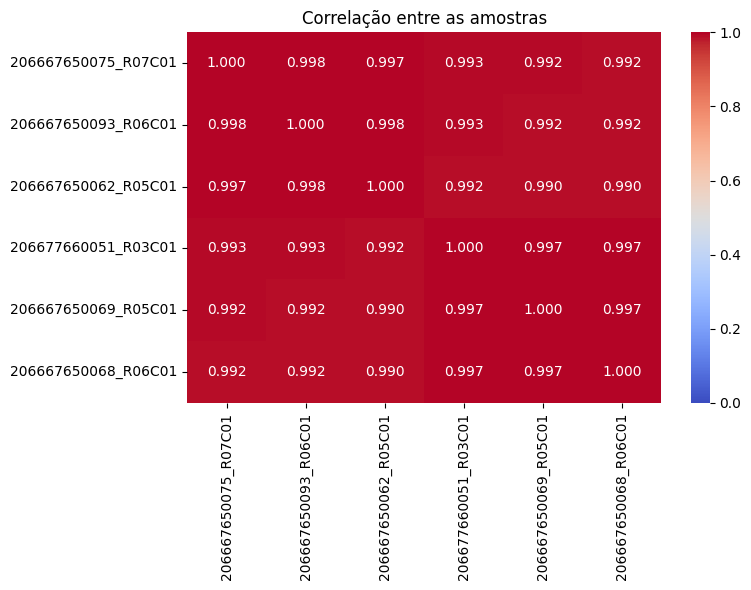

,206667650075_R07C01,206667650093_R06C01,206667650062_R05C01,206677660051_R03C01,206667650069_R05C01,206667650068_R06C01
206667650075_R07C01,1.0000,0.9976,0.9968,0.9926,0.9922,0.9921
206667650093_R06C01,0.9976,1.0000,0.9977,0.9927,0.9920,0.9918
206667650062_R05C01,0.9968,0.9977,1.0000,0.9921,0.9900,0.9903
206677660051_R03C01,0.9926,0.9927,0.9921,1.0000,0.9965,0.9975
206667650069_R05C01,0.9922,0.9920,0.9900,0.9965,1.0000,0.9974
206667650068_R06C01,0.9921,0.9918,0.9903,0.9975,0.9974,1.0000


In [ ]:
correlacao = dados.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlacao,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=0,
    vmax=1
)

plt.title("Correlação entre as amostras")
plt.tight_layout()
plt.show()

display(correlacao.round(4))

In [ ]:
import requests

url = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/esummary.fcgi"

params = {
    "db": "gds",
    "id": "200276323",
    "retmode": "json"
}

print("Identificadores das amostras na matriz:")
print(dados.columns.tolist())

Identificadores das amostras na matriz:
['206667650075_R07C01', '206667650093_R06C01', '206667650062_R05C01', '206677660051_R03C01', '206667650069_R05C01', '206667650068_R06C01']


In [ ]:
import requests

gsm_ids = [
    "GSM8496586",
    "GSM8496587",
    "GSM8496588",
    "GSM8496589",
    "GSM8496590",
    "GSM8496591"
]

for gsm in gsm_ids:
    url = f"https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc={gsm}&targ=self&form=text&view=full"
    resposta = requests.get(url, timeout=30)

    print("\n" + "=" * 60)
    print("AMOSTRA:", gsm)

    if resposta.status_code == 200:
        linhas = resposta.text.splitlines()

        for linha in linhas:
            if any(
                termo in linha.lower()
                for termo in [
                    "!sample_title",
                    "!sample_source_name_ch1",
                    "!sample_characteristics_ch1",
                    "!sample_description"
                ]
            ):
                print(linha)
    else:
        print("Erro ao consultar:", resposta.status_code)


AMOSTRA: GSM8496586
!Sample_title = Space_methylation [206667650075_R07C01]
!Sample_source_name_ch1 = Blood
!Sample_characteristics_ch1 = tissue: Blood

AMOSTRA: GSM8496587
!Sample_title = Space_methylation [206667650093_R06C01]
!Sample_source_name_ch1 = Blood
!Sample_characteristics_ch1 = tissue: Blood

AMOSTRA: GSM8496588
!Sample_title = Space_methylation [206667650062_R05C01]
!Sample_source_name_ch1 = Blood
!Sample_characteristics_ch1 = tissue: Blood

AMOSTRA: GSM8496589
!Sample_title = Space_methylation [206677660051_R03C01]
!Sample_source_name_ch1 = Blood
!Sample_characteristics_ch1 = tissue: Blood

AMOSTRA: GSM8496590
!Sample_title = Space_methylation [206667650069_R05C01]
!Sample_source_name_ch1 = Blood
!Sample_characteristics_ch1 = tissue: Blood

AMOSTRA: GSM8496591
!Sample_title = Space_methylation [206667650068_R06C01]
!Sample_source_name_ch1 = Blood
!Sample_characteristics_ch1 = tissue: Blood


In [ ]:
url_soft = (
    "https://ftp.ncbi.nlm.nih.gov/geo/series/"
    "GSE276nnn/GSE276323/soft/"
    "GSE276323_family.soft.gz"
)

resposta = requests.get(url_soft, timeout=60)
print("Status do download:", resposta.status_code)

Status do download: 200


In [ ]:
conteudo = gzip.decompress(resposta.content).decode(
    "utf-8", errors="replace"
)

for bloco in conteudo.split("^SAMPLE = ")[1:]:
    linhas = bloco.splitlines()

    print("\n" + "=" * 60)
    print("Amostra:", linhas[0])

    for linha in linhas:
        if any(
            termo in linha.lower()
            for termo in [
                "!sample_title",
                "!sample_source_name_ch1",
                "!sample_characteristics_ch1",
                "!sample_description",
                "!sample_supplementary_file"
            ]
        ):
            print(linha)


Amostra: GSM8496586
!Sample_title = Space_methylation [206667650075_R07C01]
!Sample_source_name_ch1 = Blood
!Sample_characteristics_ch1 = tissue: Blood
!Sample_supplementary_file = ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8496nnn/GSM8496586/suppl/GSM8496586_206667650075_R07C01_Grn.idat.gz
!Sample_supplementary_file = ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8496nnn/GSM8496586/suppl/GSM8496586_206667650075_R07C01_Red.idat.gz

Amostra: GSM8496587
!Sample_title = Space_methylation [206667650093_R06C01]
!Sample_source_name_ch1 = Blood
!Sample_characteristics_ch1 = tissue: Blood
!Sample_supplementary_file = ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8496nnn/GSM8496587/suppl/GSM8496587_206667650093_R06C01_Grn.idat.gz
!Sample_supplementary_file = ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8496nnn/GSM8496587/suppl/GSM8496587_206667650093_R06C01_Red.idat.gz

Amostra: GSM8496588
!Sample_title = Space_methylation [206667650062_R05C01]
!Sample_source_name_ch1 = Blood
!Sample_characteristics_ch1 =

In [ ]:
cpgs_interesse = [
    "cg21011110"
]

for cpg in cpgs_interesse:
    if cpg in dados.index:
        print(f"{cpg} encontrado na matriz")
        display(dados.loc[[cpg]])
    else:
        print(f"{cpg} não encontrado diretamente no índice")

cg21011110 encontrado na matriz


,206667650075_R07C01,206667650093_R06C01,206667650062_R05C01,206677660051_R03C01,206667650069_R05C01,206667650068_R06C01
cg21011110,0.072282,0.177975,0.065039,0.070188,0.147451,0.0675


In [ ]:
print("Exemplos de identificadores:")
print(dados.index[:20].tolist())

print("\nÍndice do tipo:", type(dados.index).__name__)

Exemplos de identificadores:
['cg26928153', 'cg16269199', 'cg13869341', 'cg24669183', 'cg26679879', 'cg22519184', 'cg15560884', 'cg01014490', 'cg10692041', 'cg09961319', 'cg02339369', 'cg17505339', 'cg09499020', 'cg16535257', 'cg15979415', 'cg11954957', 'cg04747364', 'cg26304905', 'cg20434134', 'cg16736630']

Índice do tipo: Index


In [ ]:
url_gpl = (
    "https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi"
    "?acc=GPL21145&targ=self&form=text&view=quick"
)

resposta = requests.get(url_gpl, timeout=30)

print("Status:", resposta.status_code)
print(resposta.text[:2000])

Status: 200
^PLATFORM = GPL21145
!Platform_title = Infinium MethylationEPIC
!Platform_geo_accession = GPL21145
!Platform_status = Public on Nov 16 2015
!Platform_submission_date = Nov 16 2015
!Platform_last_update_date = Jan 20 2019
!Platform_technology = oligonucleotide beads
!Platform_distribution = commercial
!Platform_organism = Homo sapiens
!Platform_taxid = 9606
!Platform_manufacturer = Illumina, Inc.
!Platform_manufacture_protocol = See manufacturer's website
!Platform_contact_name =  ,,Illumina Inc.
!Platform_contact_email = expression@illumina.com, techsupport@illumina.com
!Platform_contact_phone = 1 800 809 4566 
!Platform_contact_institute = Illumina Inc.
!Platform_contact_address = 9885 Towne Centre Drive
!Platform_contact_city = San Diego
!Platform_contact_state = CA
!Platform_contact_zip/postal_code = 92121
!Platform_contact_country = USA
!Platform_contact_web_link = www.illumina.com
!Platform_supplementary_file = ftp://ftp.ncbi.nlm.nih.gov/geo/platforms/GPL21nnn/GPL21145

In [ ]:
conteudo = gzip.decompress(resposta.content)

print(conteudo[:3000].decode("utf-8", errors="replace"))


Illumina, Inc.,,,,,,,,,,,,,,,,,,,,,,,,,
[Heading],,,,,,,,,,,,,,,,,,,,,,,,,,
Descriptor File Name,MethylationEPIC_15073387_v-1-0.csv.bpm,,,,,,,,,,,,,,,,,,,,,,,,,
Assay Format,Infinium 2,,,,,,,,,,,,,,,,,,,,,,,,,
Date Manufactured,11/5/2015,,,,,,,,,,,,,,,,,,,,,,,,,
Loci Count,867926,,,,,,,,,,,,,,,,,,,,,,,,,
[Assay],,,,,,,,,,,,,,,,,,,,,,,,,,
IlmnID,Name,AddressA_ID,AlleleA_ProbeSeq,AddressB_ID,AlleleB_ProbeSeq,Infinium_Design_Type,Next_Base,Color_Channel,Forward_Sequence,Genome_Build,CHR,MAPINFO,SourceSeq,UCSC_RefGene_Name,UCSC_RefGene_Accession,UCSC_RefGene_Group,UCSC_CpG_Islands_Name,Relation_to_UCSC_CpG_Island,Phantom4_Enhancers,Phantom5_Enhancers,DMR,450k_Enhancer,HMM_Island,Regulatory_Feature_Name,Regulatory_Feature_Group,GencodeBasicV12_NAME,GencodeBasicV12_Accession,GencodeBasicV12_Group,GencodeCompV12_NAME,GencodeCompV12_Accession,GencodeCompV12_Group,DNase_Hypersensitivity_NAME,DNase_Hypersensitivity_Evidence_Count,OpenChromatin_NAME,OpenChromatin_Evidence_Count,TFBS_NAME,TFBS_Evi

In [ ]:

anotacao_gpl = pd.read_csv(
    BytesIO(resposta.content),
    compression="gzip",
    dtype=str,
    engine="python",
    on_bad_lines="warn"
)

print("Dimensões:", anotacao_gpl.shape)
print("\nColunas disponíveis:")
print(anotacao_gpl.columns.tolist())

display(anotacao_gpl.head())



A saída de streaming foi truncada nas últimas 5000 linhas.

  anotacao_gpl = pd.read_csv(
/tmp/ipykernel_6527/202758176.py:1: ParserWarning: Skipping line 866907: Expected 27 fields in line 866907, saw 46

  anotacao_gpl = pd.read_csv(
/tmp/ipykernel_6527/202758176.py:1: ParserWarning: Skipping line 866908: Expected 27 fields in line 866908, saw 46

  anotacao_gpl = pd.read_csv(
/tmp/ipykernel_6527/202758176.py:1: ParserWarning: Skipping line 866909: Expected 27 fields in line 866909, saw 46

  anotacao_gpl = pd.read_csv(
/tmp/ipykernel_6527/202758176.py:1: ParserWarning: Skipping line 866910: Expected 27 fields in line 866910, saw 46

  anotacao_gpl = pd.read_csv(
/tmp/ipykernel_6527/202758176.py:1: ParserWarning: Skipping line 866911: Expected 27 fields in line 866911, saw 46

  anotacao_gpl = pd.read_csv(
/tmp/ipykernel_6527/202758176.py:1: ParserWarning: Skipping line 866912: Expected 27 fields in line 866912, saw 46

  anotacao_gpl = pd.read_csv(
/tmp/ipykernel_6527/202758176.py:1

Dimensões: (7, 27)

Colunas disponíveis:
['Illumina', ' Inc.', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Unnamed: 17', 'Unnamed: 18', 'Unnamed: 19', 'Unnamed: 20', 'Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25', 'Unnamed: 26']


,Illumina,Inc.,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25,Unnamed: 26
0,[Heading],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Descriptor File Name,MethylationEPIC_15073387_v-1-0.csv.bpm,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Assay Format,Infinium 2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Date Manufactured,11/5/2015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Loci Count,867926,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:

for coluna in anotacao_gpl.columns:
    if any(
        termo in coluna.lower()
        for termo in ["name", "gene", "symbol", "chr", "mapinfo", "ilmnid"]
    ):
        print(coluna)


Unnamed: 2
Unnamed: 3
Unnamed: 4
Unnamed: 5
Unnamed: 6
Unnamed: 7
Unnamed: 8
Unnamed: 9
Unnamed: 10
Unnamed: 11
Unnamed: 12
Unnamed: 13
Unnamed: 14
Unnamed: 15
Unnamed: 16
Unnamed: 17
Unnamed: 18
Unnamed: 19
Unnamed: 20
Unnamed: 21
Unnamed: 22
Unnamed: 23
Unnamed: 24
Unnamed: 25
Unnamed: 26


In [ ]:

print("Status HTTP:", resposta.status_code)
print("Tamanho do download:", len(resposta.content), "bytes")
print("Início do arquivo:")
print(gzip.decompress(resposta.content)[:500].decode("utf-8", errors="replace"))


Status HTTP: 200
Tamanho do download: 169013044 bytes
Início do arquivo:
Illumina, Inc.,,,,,,,,,,,,,,,,,,,,,,,,,
[Heading],,,,,,,,,,,,,,,,,,,,,,,,,,
Descriptor File Name,MethylationEPIC_15073387_v-1-0.csv.bpm,,,,,,,,,,,,,,,,,,,,,,,,,
Assay Format,Infinium 2,,,,,,,,,,,,,,,,,,,,,,,,,
Date Manufactured,11/5/2015,,,,,,,,,,,,,,,,,,,,,,,,,
Loci Count,867926,,,,,,,,,,,,,,,,,,,,,,,,,
[Assay],,,,,,,,,,,,,,,,,,,,,,,,,,
IlmnID,Name,AddressA_ID,AlleleA_ProbeSeq,AddressB_ID,AlleleB_ProbeSeq,Infinium_Design_Type,Next_Base,Color_Channel,Forward_Sequence,Genome_Build,CHR,MAPINFO,Sou


In [ ]:

print("Exemplo de IDs da matriz:")
print(dados.index[:10].tolist())

print("\nO CpG de interesse está na matriz?")
print("cg21011110" in dados.index)


Exemplo de IDs da matriz:
['cg26928153', 'cg16269199', 'cg13869341', 'cg24669183', 'cg26679879', 'cg22519184', 'cg15560884', 'cg01014490', 'cg10692041', 'cg09961319']

O CpG de interesse está na matriz?
True


In [30]:

!apt-get -qq update
!apt-get -qq install -y r-base
!R -e 'if (!requireNamespace("BiocManager", quietly=TRUE)) install.packages("BiocManager", repos="https://cloud.r-project.org"); BiocManager::install("IlluminaHumanMethylationEPICanno.ilm10b4.hg19", ask=FALSE, update=FALSE)'


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)

R version 4.6.1 (2026-06-24) -- "Happy Hop"
Copyright (C) 2026 The R Foundation for Statistical Computing
Platform: x86_64-pc-linux-gnu

R is free software and comes with ABSOLUTELY NO WARRANTY.
You are welcome to redistribute it under certain conditions.
Type 'license()' or 'licence()' for distribution details.

  Natural language support but running in an English locale

R is a collaborative project with many contributors.
Type 'contributors()' for more information and
'citation()' on how to cite R or R packages in publications.

Type 'demo()' for some demos, 'help()' for on-line help, or
'help.start()' for an HTML browser interface to help.
Type 'q()' to quit R.

> if (!requireNamespace("BiocManager", quietly=TRUE)) install.packages("BiocManager", repos="https://cloud.r-project.org"); BiocManager

In [31]:

!R -e 'library(IlluminaHumanMethylationEPICanno.ilm10b4.hg19); library(minfi); a <- getAnnotation(IlluminaHumanMethylationEPICanno.ilm10b4.hg19); cat("Total de CpGs:", nrow(a), "\n"); cat("Colunas:", paste(names(a), collapse=", "), "\n"); write.csv(as.data.frame(a), "/content/anotacao_epic.csv", row.names=TRUE)'



R version 4.6.1 (2026-06-24) -- "Happy Hop"
Copyright (C) 2026 The R Foundation for Statistical Computing
Platform: x86_64-pc-linux-gnu

R is free software and comes with ABSOLUTELY NO WARRANTY.
You are welcome to redistribute it under certain conditions.
Type 'license()' or 'licence()' for distribution details.

  Natural language support but running in an English locale

R is a collaborative project with many contributors.
Type 'contributors()' for more information and
'citation()' on how to cite R or R packages in publications.

Type 'demo()' for some demos, 'help()' for on-line help, or
'help.start()' for an HTML browser interface to help.
Type 'q()' to quit R.

> library(IlluminaHumanMethylationEPICanno.ilm10b4.hg19); library(minfi); a <- getAnnotation(IlluminaHumanMethylationEPICanno.ilm10b4.hg19); cat("Total de CpGs:", nrow(a), "\n"); cat("Colunas:", paste(names(a), collapse=", "), "\n"); write.csv(as.data.frame(a), "/content/anotacao_epic.csv", row.names=TRUE)
Loading required

In [32]:
# Carregar a anotação exportada pelo R
anotacao = pd.read_csv(
    "/content/anotacao_epic.csv",
    index_col=0
)

print("Dimensões da matriz de metilação:", dados.shape)
print("Dimensões da anotação:", anotacao.shape)

# Conferir se os identificadores estão no mesmo formato
print("\nExemplos de CpGs da matriz:")
print(dados.index[:5].tolist())

print("\nExemplos de CpGs da anotação:")
print(anotacao.index[:5].tolist())

# Identificar os CpGs presentes nas duas tabelas
cpgs_comuns = dados.index.intersection(anotacao.index)

print("\nCpGs encontrados nas duas tabelas:", len(cpgs_comuns))
print(
    "Percentual da matriz anotada:",
    round(len(cpgs_comuns) / len(dados.index) * 100, 2),
    "%"
)


/tmp/ipykernel_6527/4025883433.py:2: DtypeWarning: Columns (8,10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  anotacao = pd.read_csv(


Dimensões da matriz de metilação: (776047, 6)
Dimensões da anotação: (865859, 46)

Exemplos de CpGs da matriz:
['cg26928153', 'cg16269199', 'cg13869341', 'cg24669183', 'cg26679879']

Exemplos de CpGs da anotação:
['cg18478105', 'cg09835024', 'cg14361672', 'cg01763666', 'cg12950382']

CpGs encontrados nas duas tabelas: 776047
Percentual da matriz anotada: 100.0 %


In [33]:

# Genes candidatos para a análise exploratória
genes_interesse = ["FBLIM1", "IHH", "SCAMP2"]

# Selecionar os CpGs que aparecem na matriz e na anotação
anotacao_comum = anotacao.loc[
    anotacao.index.intersection(dados.index)
].copy()

# Procurar os genes na coluna de anotação
coluna_genes = "UCSC_RefGene_Name"

for gene in genes_interesse:
    filtro = anotacao_comum[coluna_genes].fillna("").astype(str).str.split(";").apply(
        lambda lista: gene in [g.strip() for g in lista]
    )

    encontrados = anotacao_comum.loc[filtro]

    print(f"\n{'=' * 45}")
    print(f"Gene: {gene}")
    print("Número de CpGs associados:", len(encontrados))

    if not encontrados.empty:
        colunas_exibir = [
            coluna for coluna in [
                "chr",
                "pos",
                "UCSC_RefGene_Name",
                "UCSC_RefGene_Group",
                "Relation_to_Island"
            ]
            if coluna in encontrados.columns
        ]

        display(encontrados[colunas_exibir].head(10))
    else:
        print("Nenhum CpG encontrado para esse gene.")



Gene: FBLIM1
Número de CpGs associados: 37


,chr,pos,UCSC_RefGene_Name,UCSC_RefGene_Group,Relation_to_Island
cg23002761,chr1,16085642,FBLIM1,5'UTR,Island
cg17332369,chr1,16112370,FBLIM1;FBLIM1,3'UTR;3'UTR,OpenSea
cg25494767,chr1,16085237,FBLIM1,TSS200,Island
cg15816719,chr1,16085170,FBLIM1,TSS200,Island
cg11780735,chr1,16085172,FBLIM1,TSS200,Island
cg26036626,chr1,16085597,FBLIM1,5'UTR,Island
cg17276021,chr1,16084445,FBLIM1,TSS1500,N_Shore
cg14531560,chr1,16085371,FBLIM1,5'UTR,Island
cg04897742,chr1,16085148,FBLIM1,TSS200,Island
cg13484546,chr1,16084939,FBLIM1,TSS1500,N_Shore



Gene: IHH
Número de CpGs associados: 26


,chr,pos,UCSC_RefGene_Name,UCSC_RefGene_Group,Relation_to_Island
cg07045816,chr2,219925260,IHH,TSS200,Island
cg25908985,chr2,219925065,IHH,1stExon,Island
cg22281638,chr2,219920345,IHH,Body,Island
cg24212621,chr2,219920517,IHH,Body,Island
cg25297849,chr2,219922998,IHH,Body,Island
cg17178336,chr2,219925246,IHH,TSS200,Island
cg08957652,chr2,219925251,IHH,TSS200,Island
cg03292754,chr2,219925311,IHH,TSS200,Island
cg12565637,chr2,219925248,IHH,TSS200,Island
cg08261878,chr2,219925330,IHH,TSS200,Island



Gene: SCAMP2
Número de CpGs associados: 26


,chr,pos,UCSC_RefGene_Name,UCSC_RefGene_Group,Relation_to_Island
cg26769250,chr15,75165338,SCAMP2,Body,N_Shore
cg13316255,chr15,75165642,SCAMP2;SCAMP2,5'UTR;1stExon,Island
cg09962198,chr15,75165438,SCAMP2,Body,Island
cg02007571,chr15,75165806,SCAMP2,TSS200,Island
cg10253484,chr15,75165896,SCAMP2,TSS1500,Island
cg25367418,chr15,75165840,SCAMP2,TSS200,Island
cg03289416,chr15,75166202,SCAMP2,TSS1500,S_Shore
cg23881083,chr15,75152168,SCAMP2,Body,OpenSea
cg26451198,chr15,75146573,SCAMP2,Body,OpenSea
cg04949287,chr15,75165871,SCAMP2,TSS1500,Island


In [34]:

# Genes candidatos
genes_interesse = ["FBLIM1", "IHH", "SCAMP2"]

# Selecionar CpGs associados a cada gene
resultados = []

for gene in genes_interesse:
    filtro = (
        anotacao_comum["UCSC_RefGene_Name"]
        .fillna("")
        .astype(str)
        .str.split(";")
        .apply(lambda lista: gene in [g.strip() for g in lista])
    )

    cpgs_gene = anotacao_comum.loc[filtro].copy()

    # Adicionar valores de metilação das seis amostras
    valores = dados.loc[cpgs_gene.index]

    tabela_gene = cpgs_gene[
        [
            coluna for coluna in [
                "chr",
                "pos",
                "UCSC_RefGene_Name",
                "UCSC_RefGene_Group",
                "Relation_to_Island"
            ]
            if coluna in cpgs_gene.columns
        ]
    ].join(valores)

    tabela_gene.insert(0, "Gene_candidato", gene)
    resultados.append(tabela_gene)

tabela_cpgs = pd.concat(resultados)

print("Total de CpGs na tabela:", len(tabela_cpgs))
display(tabela_cpgs.head(15))


Total de CpGs na tabela: 89


,Gene_candidato,chr,pos,UCSC_RefGene_Name,UCSC_RefGene_Group,Relation_to_Island,206667650075_R07C01,206667650093_R06C01,206667650062_R05C01,206677660051_R03C01,206667650069_R05C01,206667650068_R06C01
cg23002761,FBLIM1,chr1,16085642,FBLIM1,5'UTR,Island,0.188826,0.195614,0.092503,0.090301,0.213983,0.095091
cg17332369,FBLIM1,chr1,16112370,FBLIM1;FBLIM1,3'UTR;3'UTR,OpenSea,0.841241,0.849093,0.850595,0.860375,0.858152,0.859790
cg25494767,FBLIM1,chr1,16085237,FBLIM1,TSS200,Island,0.517888,0.457617,0.201522,0.528414,0.544178,0.500731
cg15816719,FBLIM1,chr1,16085170,FBLIM1,TSS200,Island,0.169964,0.191938,0.205446,0.185304,0.206536,0.185510
cg11780735,FBLIM1,chr1,16085172,FBLIM1,TSS200,Island,0.217974,0.225762,0.224583,0.216192,0.238030,0.226215
cg26036626,FBLIM1,chr1,16085597,FBLIM1,5'UTR,Island,0.254692,0.313182,0.100137,0.123666,0.351224,0.114902
cg17276021,FBLIM1,chr1,16084445,FBLIM1,TSS1500,N_Shore,0.539245,0.548437,0.535560,0.532428,0.476519,0.481600
cg14531560,FBLIM1,chr1,16085371,FBLIM1,5'UTR,Island,0.062286,0.070423,0.073268,0.072557,0.069889,0.069599
cg04897742,FBLIM1,chr1,16085148,FBLIM1,TSS200,Island,0.089239,0.091350,0.095144,0.105168,0.107104,0.117969
cg13484546,FBLIM1,chr1,16084939,FBLIM1,TSS1500,N_Shore,0.290210,0.303599,0.317263,0.290137,0.273729,0.271579


In [35]:

# Nomes das seis colunas que contêm os valores de metilação
colunas_amostras = dados.columns.tolist()

# Calcular estatísticas para cada CpG dos genes candidatos
tabela_variacao = tabela_cpgs.copy()

tabela_variacao["Media_metilacao"] = (
    tabela_variacao[colunas_amostras].mean(axis=1)
)

tabela_variacao["Desvio_padrao"] = (
    tabela_variacao[colunas_amostras].std(axis=1)
)

tabela_variacao["Amplitude"] = (
    tabela_variacao[colunas_amostras].max(axis=1)
    - tabela_variacao[colunas_amostras].min(axis=1)
)

# Mostrar os 15 CpGs com maior amplitude
maiores_variacoes = tabela_variacao.sort_values(
    "Amplitude",
    ascending=False
)

colunas_resultado = [
    "Gene_candidato",
    "chr",
    "pos",
    "UCSC_RefGene_Group",
    "Media_metilacao",
    "Desvio_padrao",
    "Amplitude"
]

display(maiores_variacoes[colunas_resultado].head(15).round(4))


,Gene_candidato,chr,pos,UCSC_RefGene_Group,Media_metilacao,Desvio_padrao,Amplitude
cg25908985,IHH,chr2,219925065,1stExon,0.3447,0.3025,0.8300
cg25494767,FBLIM1,chr1,16085237,TSS200,0.4584,0.1293,0.3427
cg26036626,FBLIM1,chr1,16085597,5'UTR,0.2096,0.1106,0.2511
cg26769250,SCAMP2,chr15,75165338,Body,0.2238,0.0981,0.2039
cg13316255,SCAMP2,chr15,75165642,5'UTR;1stExon,0.1861,0.0889,0.1884
cg23002761,FBLIM1,chr1,16085642,5'UTR,0.1461,0.0591,0.1237
cg09617556,IHH,chr2,219924408,Body,0.3609,0.0470,0.1156
cg25719573,FBLIM1,chr1,16087295,5'UTR,0.6193,0.0525,0.1071
cg10386217,FBLIM1,chr1,16103552,Body;Body,0.3621,0.0433,0.1058
cg25297849,IHH,chr2,219922998,Body,0.0956,0.0419,0.0933


In [36]:

# Selecionar os cinco CpGs com maior amplitude
top_cpgs = maiores_variacoes.head(5).copy()

# Organizar os valores de metilação para comparação
colunas_amostras = dados.columns.tolist()

valores_top = top_cpgs[
    ["Gene_candidato", "UCSC_RefGene_Group"] + colunas_amostras
].copy()

valores_top = valores_top.set_index(
    pd.Index(top_cpgs.index, name="CpG")
)

display(valores_top.round(4).T)


CpG,cg25908985,cg25494767,cg26036626,cg26769250,cg13316255
Gene_candidato,IHH,FBLIM1,FBLIM1,SCAMP2,SCAMP2
UCSC_RefGene_Group,1stExon,TSS200,5'UTR,Body,5'UTR;1stExon
206667650075_R07C01,0.2448,0.5179,0.2547,0.2926,0.1778
206667650093_R06C01,0.1797,0.4576,0.3132,0.2502,0.2667
206667650062_R05C01,0.2986,0.2015,0.1001,0.0987,0.2526
206677660051_R03C01,0.1167,0.5284,0.1237,0.3026,0.08
206667650069_R05C01,0.2819,0.5442,0.3512,0.2985,0.2612
206667650068_R06C01,0.9466,0.5007,0.1149,0.1002,0.0783


In [37]:

# Valores do CpG cg25908985 nas seis amostras
cpg = "cg25908985"

valores_cpg = dados.loc[cpg]

display(
    valores_cpg.rename("Metilacao").to_frame()
    .sort_values("Metilacao", ascending=False)
    .round(4)
)

print("Mínimo:", round(valores_cpg.min(), 4))
print("Máximo:", round(valores_cpg.max(), 4))
print("Amplitude:", round(valores_cpg.max() - valores_cpg.min(), 4))


,Metilacao
206667650068_R06C01,0.9466
206667650062_R05C01,0.2986
206667650069_R05C01,0.2819
206667650075_R07C01,0.2448
206667650093_R06C01,0.1797
206677660051_R03C01,0.1167


Mínimo: 0.1167
Máximo: 0.9466
Amplitude: 0.83


In [38]:
# Códigos das amostras disponibilizados pelo GEO
metadados_geo = pd.DataFrame({
    "Amostra_GEO": [
        "GSM8496586",
        "GSM8496587",
        "GSM8496588",
        "GSM8496589",
        "GSM8496590",
        "GSM8496591"
    ],
    "Coluna_matriz": dados.columns.tolist()
})

display(metadados_geo)

,Amostra_GEO,Coluna_matriz
0,GSM8496586,206667650075_R07C01
1,GSM8496587,206667650093_R06C01
2,GSM8496588,206667650062_R05C01
3,GSM8496589,206677660051_R03C01
4,GSM8496590,206667650069_R05C01
5,GSM8496591,206667650068_R06C01


In [39]:
import requests
import re
import pandas as pd
from IPython.display import display

gsm_ids = [
    "GSM8496586",
    "GSM8496587",
    "GSM8496588",
    "GSM8496589",
    "GSM8496590",
    "GSM8496591"
]

resultados = []

for gsm in gsm_ids:
    url = (
        "https://www.ncbi.nlm.nih.gov/geo/query/"
        f"acc.cgi?acc={gsm}&targ=self&form=text&view=full"
    )

    resposta = requests.get(url, timeout=30)
    texto = resposta.text

    # Procurar campos relevantes no registro do GEO
    campos = {}
    for campo in [
        "title",
        "source_name_ch1",
        "characteristics_ch1",
        "description",
        "supplementary_file"
    ]:
        encontrados = re.findall(
            rf"!Sample_{campo}\s*=\s*(.+)",
            texto,
            flags=re.IGNORECASE
        )
        campos[campo] = " | ".join(encontrados)

    resultados.append({
        "GSM": gsm,
        **campos
    })

metadados = pd.DataFrame(resultados)
display(metadados.T)

,0,1,2,3,4,5
GSM,GSM8496586,GSM8496587,GSM8496588,GSM8496589,GSM8496590,GSM8496591
title,Space_methylation [206667650075_R07C01]\r,Space_methylation [206667650093_R06C01]\r,Space_methylation [206667650062_R05C01]\r,Space_methylation [206677660051_R03C01]\r,Space_methylation [206667650069_R05C01]\r,Space_methylation [206667650068_R06C01]\r
source_name_ch1,Blood\r,Blood\r,Blood\r,Blood\r,Blood\r,Blood\r
characteristics_ch1,tissue: Blood\r,tissue: Blood\r,tissue: Blood\r,tissue: Blood\r,tissue: Blood\r,tissue: Blood\r
description,,,,,,
supplementary_file,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8496...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8496...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8496...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8496...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8496...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8496...


In [40]:
mapeamento = pd.DataFrame({
    "Coluna_matriz": dados.columns.tolist(),
    "GSM": [
        "GSM8496586",
        "GSM8496587",
        "GSM8496588",
        "GSM8496589",
        "GSM8496590",
        "GSM8496591"
    ],
    "Participante": ["PENDENTE"] * 6,
    "Momento": ["PENDENTE"] * 6
})

display(mapeamento)

,Coluna_matriz,GSM,Participante,Momento
0,206667650075_R07C01,GSM8496586,PENDENTE,PENDENTE
1,206667650093_R06C01,GSM8496587,PENDENTE,PENDENTE
2,206667650062_R05C01,GSM8496588,PENDENTE,PENDENTE
3,206677660051_R03C01,GSM8496589,PENDENTE,PENDENTE
4,206667650069_R05C01,GSM8496590,PENDENTE,PENDENTE
5,206667650068_R06C01,GSM8496591,PENDENTE,PENDENTE
